In [ ]:
import os
import sys
from pathlib import Path


import src
import keras
import tensorflow as tf
import pandas as pd

from src.config import SEED, ensure_directories, set_global_seed

ensure_directories()
set_global_seed(SEED)
accel_info = f"TF devices: {tf.config.list_physical_devices()}"
if keras.backend.backend() == "torch":
    import torch
    mps_ok = torch.backends.mps.is_available()
    accel_info = f"Apple Metal GPU (MPS): {'ACTIVE' if mps_ok else 'CPU'} (torch {torch.__version__})"
print(f"Keras: {keras.__version__} (backend={keras.backend.backend()}) | TensorFlow: {tf.__version__}")
print(f"Апаратне прискорення: {accel_info}")


Keras: 3.15.1 (backend=tensorflow) | TensorFlow: 2.21.0
Апаратне прискорення: TF devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


Found 19997 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.
Found 2502 files belonging to 2 classes.
Epoch 1/8
313/313 - 182s - 580ms/step - accuracy: 0.5968 - auc: 0.6366 - loss: 0.6582 - val_accuracy: 0.6729 - val_auc: 0.7424 - val_loss: 0.6049
Epoch 2/8
313/313 - 190s - 606ms/step - accuracy: 0.6830 - auc: 0.7422 - loss: 0.5964 - val_accuracy: 0.6873 - val_auc: 0.7732 - val_loss: 0.5813
Epoch 3/8
313/313 - 191s - 611ms/step - accuracy: 0.7153 - auc: 0.7829 - loss: 0.5615 - val_accuracy: 0.7466 - val_auc: 0.8219 - val_loss: 0.5310
Epoch 4/8
313/313 - 193s - 616ms/step - accuracy: 0.7607 - auc: 0.8327 - loss: 0.5056 - val_accuracy: 0.7766 - val_auc: 0.8747 - val_loss: 0.4825
Epoch 5/8
313/313 - 193s - 616ms/step - accuracy: 0.7939 - auc: 0.8714 - loss: 0.4505 - val_accuracy: 0.7854 - val_auc: 0.8974 - val_loss: 0.4607
Epoch 6/8
313/313 - 196s - 628ms/step - accuracy: 0.8214 - auc: 0.8976 - loss: 0.4054 - val_accuracy: 0.7966 - val_auc: 0.9152 - val_loss: 0.4325


/Users/bohdan_best/Documents/університет/4 курс/Deep Learning/lab8/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


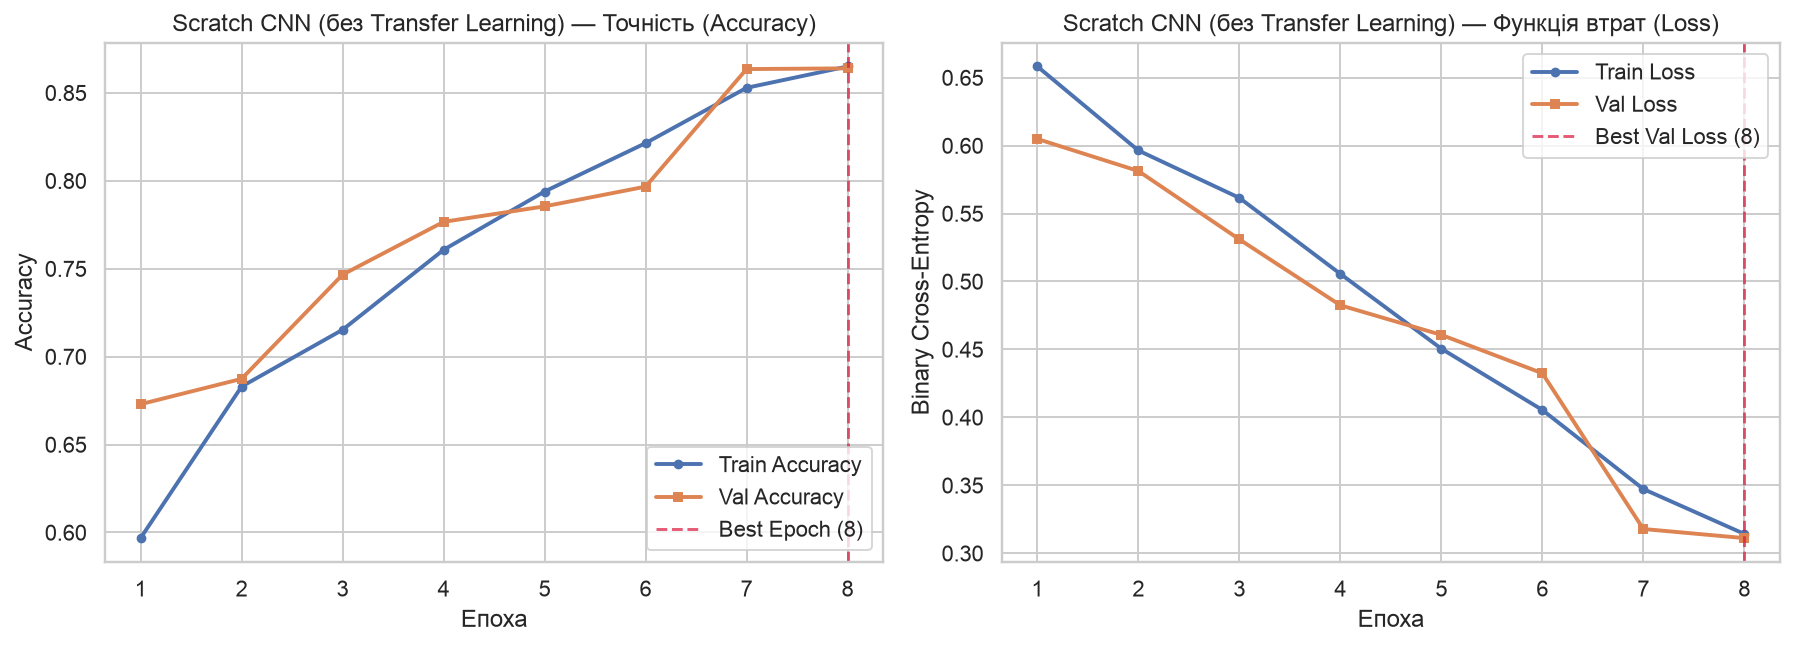

In [2]:
import json
import time
import numpy as np

from src.config import HISTORIES_DIR, MODELS_DIR, RESULTS_DIR
from src.dataset import create_image_datasets
from src.models_factory import build_scratch_cnn_baseline, count_model_parameters
from src.trainer import compute_binary_metrics, predict_external_images, release_memory
from src.visualization import (
    plot_confusion_matrix,
    plot_external_predictions_grid,
    plot_models_comparison,
    plot_training_curves,
)

baseline_summary_path = HISTORIES_DIR / "scratch_cnn_final_summary.json"
baseline_model_path = MODELS_DIR / "scratch_cnn_lab7_baseline.keras"

if baseline_summary_path.exists() and baseline_model_path.exists():
    baseline_summary = json.loads(baseline_summary_path.read_text(encoding="utf-8"))
    print(f"Завантажено збережений результат базової CNN: Test Acc = {baseline_summary['test_metrics']['accuracy']*100:.2f}%")
else:
    release_memory()
    train_ds_150, val_ds_150, test_ds_150 = create_image_datasets(image_size=(150, 150), batch_size=64)
    scratch_model = build_scratch_cnn_baseline(image_size=(150, 150))

    t0 = time.perf_counter()
    hist_obj = scratch_model.fit(train_ds_150, validation_data=val_ds_150, epochs=8, verbose=2)
    train_sec = time.perf_counter() - t0

    test_probs = scratch_model.predict(test_ds_150, verbose=0)
    test_y = np.concatenate([y.numpy() for _, y in test_ds_150], axis=0).reshape(-1)
    test_metrics = compute_binary_metrics(test_y, test_probs)

    scratch_model.save(baseline_model_path)
    size_mb = round(baseline_model_path.stat().st_size / (1024 * 1024), 2)
    param_stats = count_model_parameters(scratch_model)
    hist_dict = {k: [round(float(v), 6) for v in vals] for k, vals in hist_obj.history.items()}

    baseline_summary = {
        "model_key": "scratch_cnn",
        "display_name": "Scratch CNN (Lab 7)",
        "dropout_rate": 0.5,
        "epochs": 8,
        "best_epoch": int(np.argmin(hist_dict["val_loss"]) + 1),
        "best_val_loss": round(float(min(hist_dict["val_loss"])), 5),
        "best_val_accuracy": round(float(max(hist_dict["val_accuracy"])), 5),
        "final_train_accuracy": hist_dict["accuracy"][-1],
        "final_val_accuracy": hist_dict["val_accuracy"][-1],
        "overfitting_acc_gap": round(hist_dict["accuracy"][-1] - hist_dict["val_accuracy"][-1], 5),
        "save_filename": baseline_model_path.name,
        "model_size_mb": size_mb,
        "image_size": [150, 150],
        "preprocess_description": "Rescaling [0, 1] (no pretrained weights)",
        "extraction_seconds": 0.0,
        "head_train_seconds": round(train_sec, 2),
        "total_pipeline_seconds": round(train_sec, 2),
        **param_stats,
        "test_metrics": test_metrics,
        "history": hist_dict,
    }
    baseline_summary_path.write_text(json.dumps(baseline_summary, indent=2, ensure_ascii=False), encoding="utf-8")
    del scratch_model
    release_memory()

plot_training_curves(baseline_summary, title_prefix="Scratch CNN (без Transfer Learning)", save_name="05_scratch_cnn_curves.png")


In [ ]:
ordered_keys = ["scratch_cnn", "vgg16", "resnet50", "inception_v3", "mobilenet_v2"]
all_summaries = []
ext_predictions_by_model = {}

for key in ordered_keys:
    summary_file = HISTORIES_DIR / f"{key}_final_summary.json"
    summary_data = json.loads(summary_file.read_text(encoding="utf-8"))
    model_file = MODELS_DIR / summary_data["save_filename"]
    df_ext = predict_external_images(model_file)
    ext_predictions_by_model[summary_data["display_name"]] = df_ext
    summary_data["external_accuracy"] = round(float(df_ext["correct"].mean()), 4)
    all_summaries.append(summary_data)

comparison_rows = []
for s in all_summaries:
    tm = s["test_metrics"]
    comparison_rows.append(
        {
            "Model": s["display_name"],
            "Input Size": f"{s['image_size'][0]}x{s['image_size'][1]}",
            "Dropout": s["dropout_rate"],
            "Total Params": s["total_params"],
            "Trainable Params": s["trainable_params"],
            "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
            "Test Loss": round(tm["loss"], 4),
            "ROC-AUC": round(tm["roc_auc"], 5),
            "F1-Score": round(tm["f1"], 4),
            "External 10-Photo Acc (%)": round(s["external_accuracy"] * 100, 1),
            "Overfit Gap (%)": round(s["overfitting_acc_gap"] * 100, 2),
            "Size (MB)": s["model_size_mb"],
            "Total Time (s)": round(s["total_pipeline_seconds"], 1),
        }
    )

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison)

csv_out = RESULTS_DIR / "lab8_summary_for_lab9.csv"
json_out = RESULTS_DIR / "lab8_summary_for_lab9.json"
df_comparison.to_csv(csv_out, index=False)
json_out.write_text(json.dumps(comparison_rows, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Збережено таблицю для Лабораторної №9: {csv_out}")


Збережено таблицю для Лабораторної №9: /Users/bohdan_best/Documents/університет/4 курс/Deep Learning/lab8/results/lab8_summary_for_lab9.csv


,Model,Input Size,Dropout,Total Params,Trainable Params,Test Accuracy (%),Test Loss,ROC-AUC,F1-Score,External 10-Photo Acc (%),Overfit Gap (%),Size (MB),Total Time (s)
0,Scratch CNN (Lab 7),150x150,0.5,274113,274113,86.65,0.3191,0.94715,0.8738,90.0,0.11,3.20,1539.7
1,VGG16,224x224,0.7,14846273,131585,98.84,0.0352,0.99892,0.9884,100.0,0.60,56.73,700.0
2,ResNet50,224x224,0.5,24112513,524801,99.20,0.0230,0.99936,0.9920,100.0,0.65,92.62,869.9
3,InceptionV3,299x299,0.5,22327585,524801,99.32,0.0207,0.99906,0.9932,100.0,0.43,86.24,766.3
4,MobileNetV2,224x224,0.5,2586177,328193,98.84,0.0302,0.99889,0.9885,100.0,0.77,10.44,422.3


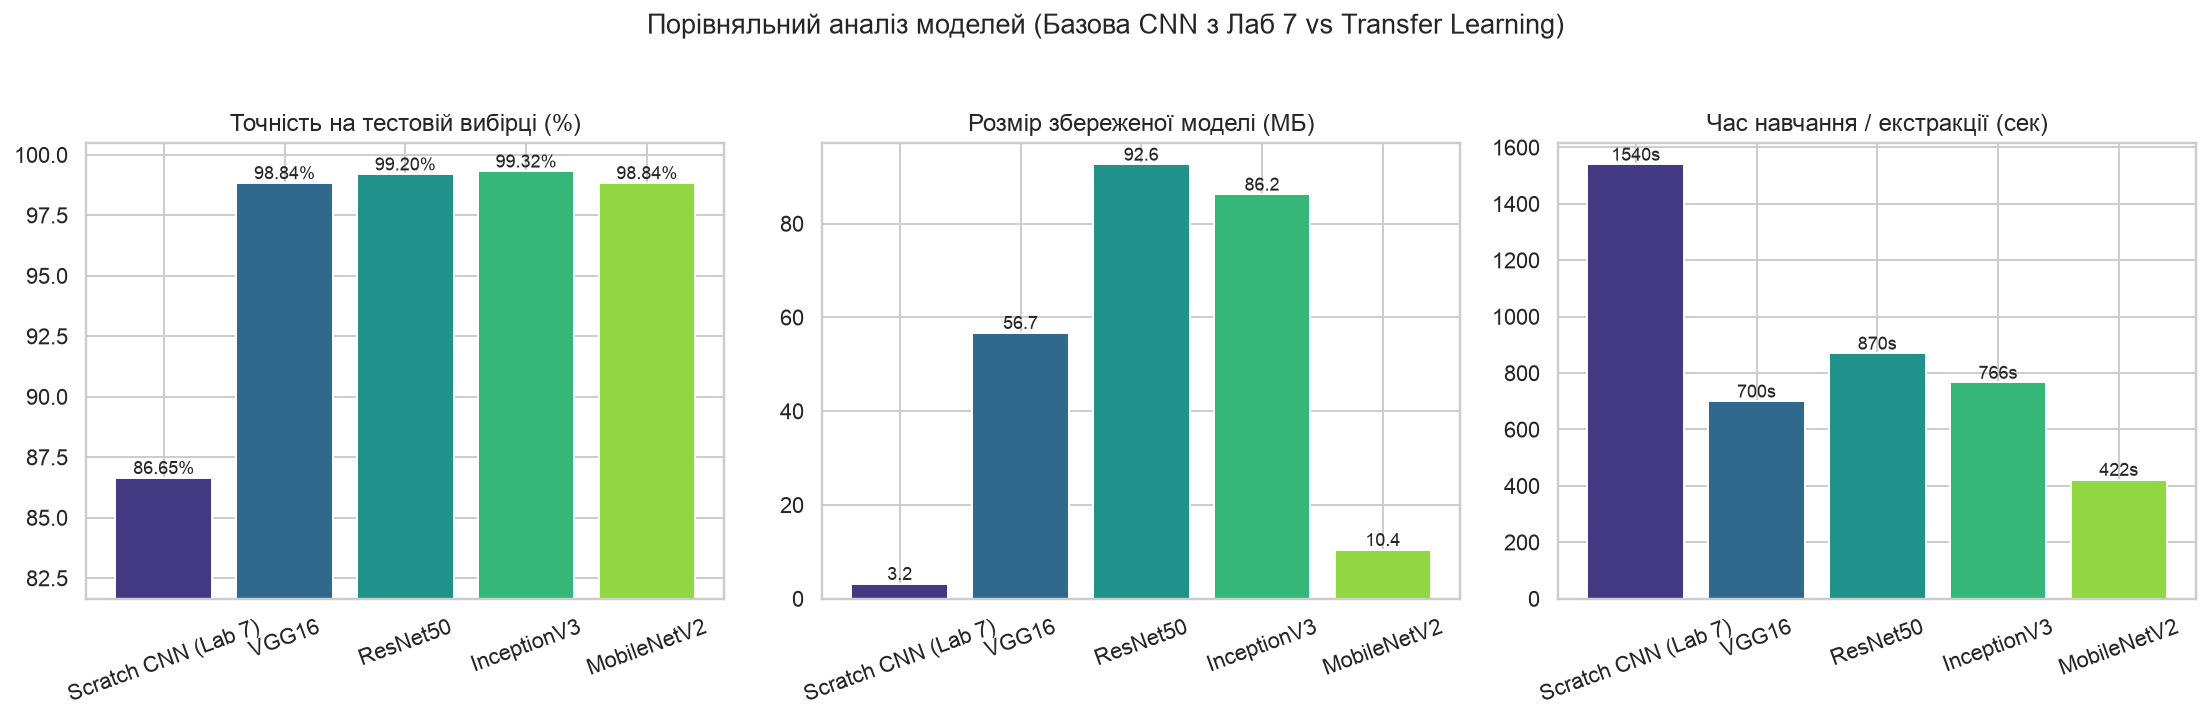

In [ ]:
plot_models_comparison(df_comparison, save_name='05_models_comparison_charts.png')

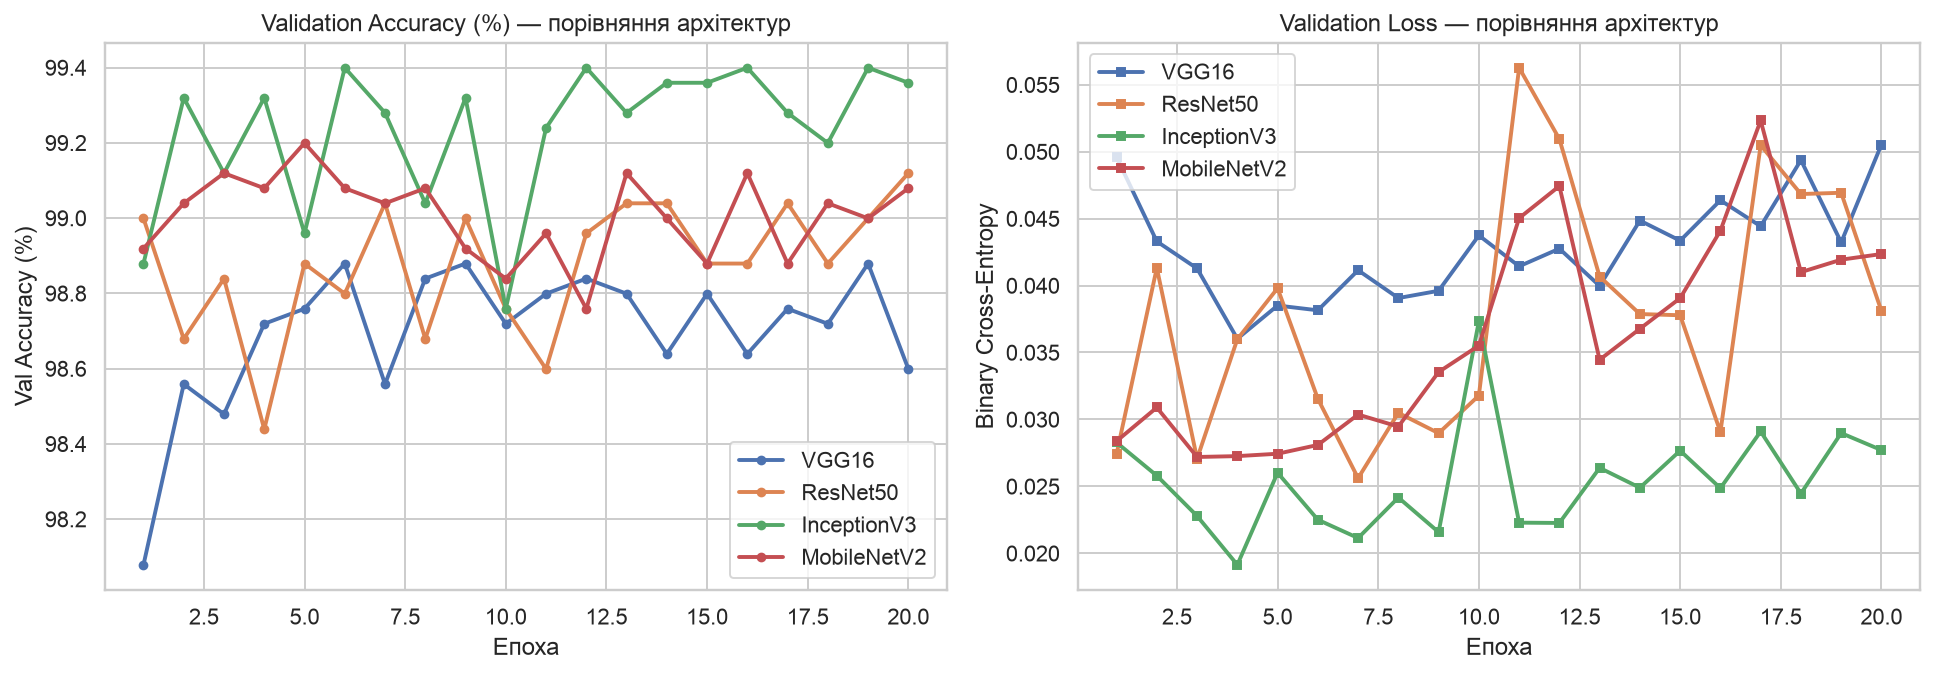

In [ ]:
import matplotlib.pyplot as plt
from src.config import FIGURES_DIR

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for s in all_summaries[1:]:
    ep = np.arange(1, len(s["history"]["val_accuracy"]) + 1)
    ax1.plot(ep, np.array(s["history"]["val_accuracy"]) * 100, "o-", linewidth=2, markersize=4, label=s["display_name"])
    ax2.plot(ep, s["history"]["val_loss"], "s-", linewidth=2, markersize=4, label=s["display_name"])

ax1.set_title("Validation Accuracy (%) — порівняння архітектур")
ax1.set_xlabel("Епоха")
ax1.set_ylabel("Val Accuracy (%)")
ax1.legend()

ax2.set_title("Validation Loss — порівняння архітектур")
ax2.set_xlabel("Епоха")
ax2.set_ylabel("Binary Cross-Entropy")
ax2.legend()

plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_tl_architectures_val_curves.png", dpi=180, bbox_inches="tight")
plt.show()


,filename,true_class,Scratch CNN (Lab 7),VGG16,ResNet50,InceptionV3,MobileNetV2
0,ext_cat_01_tabby.jpg,cats,✓ cat (79.7%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%)
1,ext_cat_02_orange.jpg,cats,✓ cat (87.1%),✓ cat (99.4%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%)
2,ext_cat_03_white_cat.jpg,cats,✓ cat (97.8%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%)
3,ext_cat_04_kitten.jpg,cats,✓ cat (73.4%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%)
4,ext_cat_05_portrait.jpg,cats,✓ cat (61.9%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%),✓ cat (100.0%)
5,ext_dog_01_golden_retriever.jpg,dogs,✓ dog (92.2%),✓ dog (100.0%),✓ dog (100.0%),✓ dog (100.0%),✓ dog (100.0%)
6,ext_dog_02_samoyed.jpg,dogs,✓ dog (89.6%),✓ dog (98.0%),✓ dog (92.7%),✓ dog (99.1%),✓ dog (53.6%)
7,ext_dog_03_beagle.jpg,dogs,✓ dog (99.9%),✓ dog (100.0%),✓ dog (100.0%),✓ dog (100.0%),✓ dog (100.0%)
8,ext_dog_04_german_shepherd.jpg,dogs,✓ dog (98.9%),✓ dog (100.0%),✓ dog (100.0%),✓ dog (100.0%),✓ dog (100.0%)
9,ext_dog_05_pug.jpg,dogs,✗ cat (72.7%),✓ dog (95.3%),✓ dog (99.9%),✓ dog (99.8%),✓ dog (99.4%)


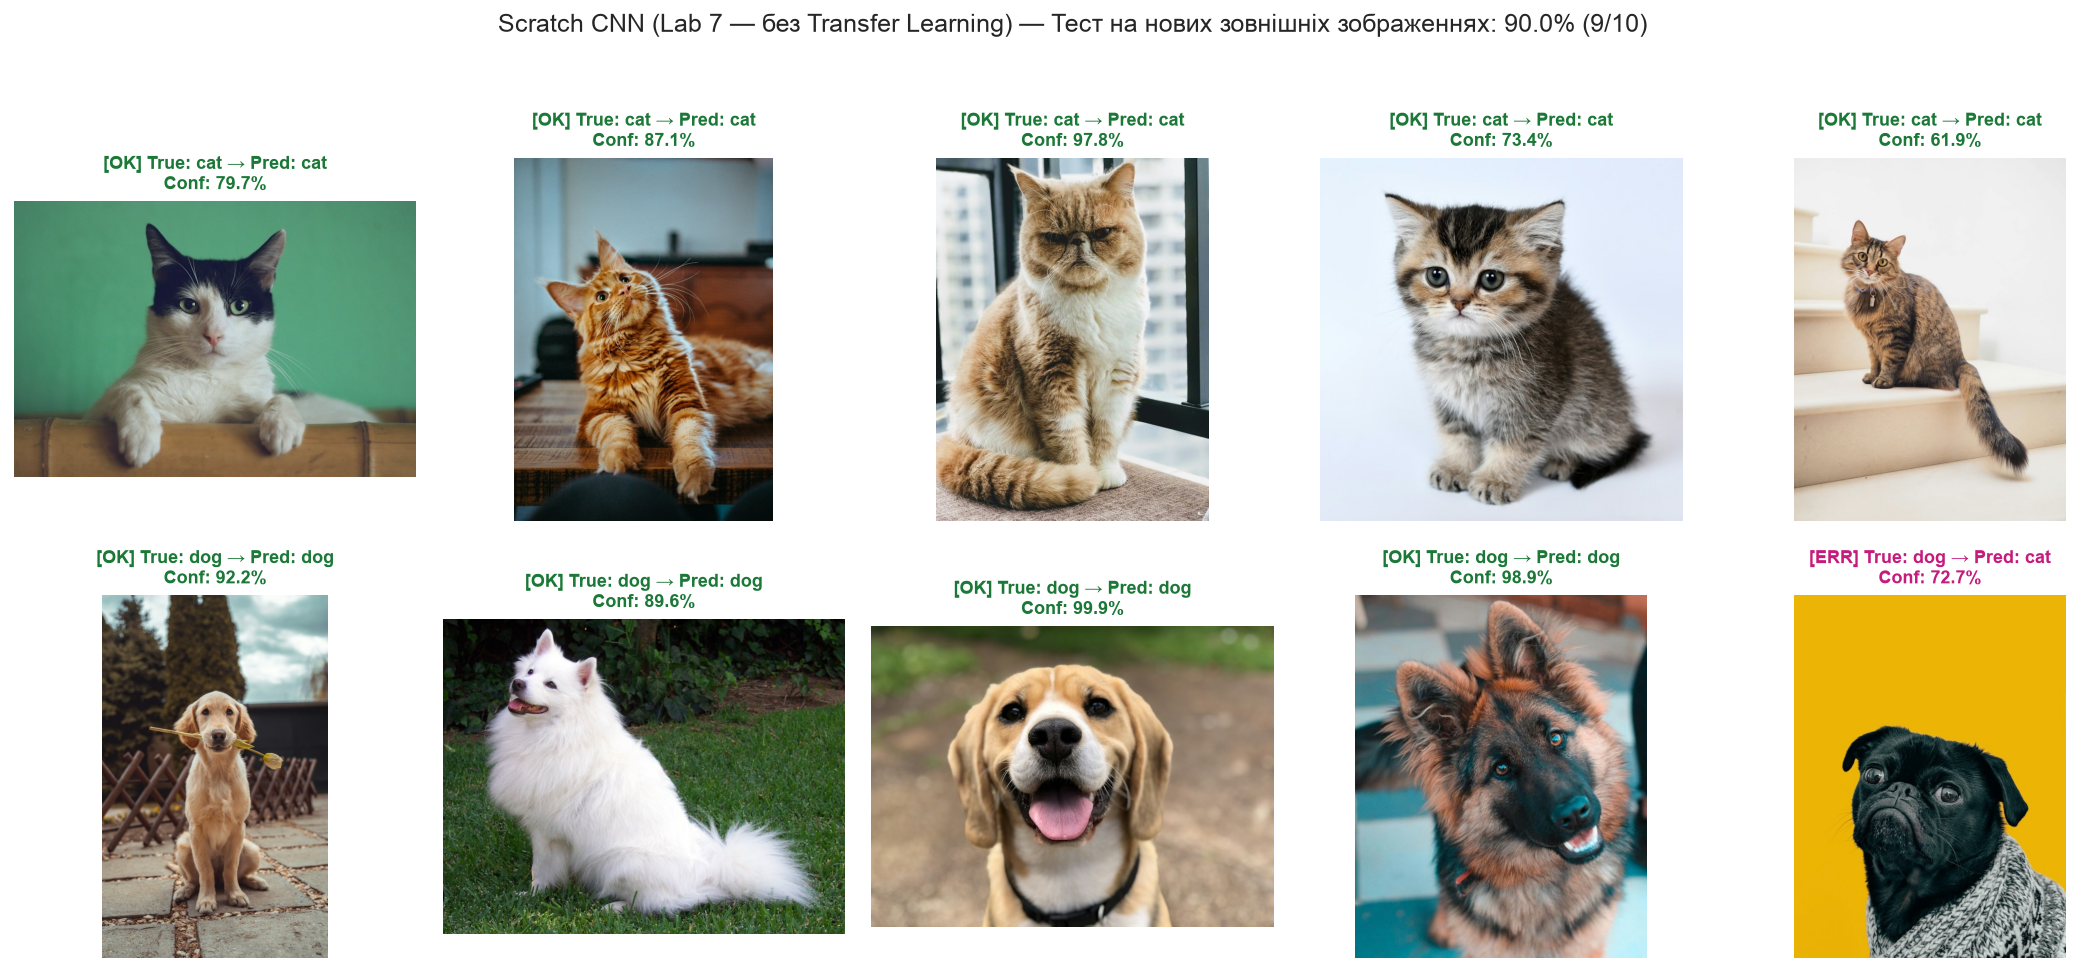

In [6]:
base_df = next(iter(ext_predictions_by_model.values()))[["filename", "true_class"]].copy()
for model_name, df_ext in ext_predictions_by_model.items():
    base_df[model_name] = [
        f"{'✓' if ok else '✗'} {pred[:-1]} ({conf*100:.1f}%)"
        for ok, pred, conf in zip(df_ext["correct"], df_ext["pred_class"], df_ext["confidence"], strict=True)
    ]

display(base_df)
plot_external_predictions_grid(
    ext_predictions_by_model["Scratch CNN (Lab 7)"],
    model_title="Scratch CNN (Lab 7 — без Transfer Learning)",
    save_name="05_scratch_cnn_external_test.png",
)
